## Computation of exercises on `10-logistic-regression.rnote`

In [1]:
import numpy as np
import pandas as pd

In [2]:
np.set_printoptions(precision=3, suppress=True, legacy="1.25")
np.set_printoptions(precision=3, suppress=True)    # NumPy arrays
pd.set_option("display.float_format", "{:.3f}".format)  # pandas DataFrames/Series
#%precision 3                                         # plain Python floats in cell output

**1.** Considere el modelo

$$
p(\mathbf{x}) = P(y = 1 \mid \mathbf{x}) = \sigma(-0.8 + 1.2x_1 - 0.5x_2).
$$

Para cada uno de los puntos $\mathbf{x}^{(1)} = (1, 2)^T$, $\mathbf{x}^{(2)} = (2, -1)^T$ y $\mathbf{x}^{(3)} = (0, 0)^T$:

- **a)** calcule el predictor lineal $z$;
- **b)** halle $P(y = 1 \mid \mathbf{x})$ y $P(y = 0 \mid \mathbf{x})$;
- **c)** determine la clase predicha.

In [3]:
X = np.array([
    [1, 1, 2],
    [1, 2, -1],
    [1, 0, 0]
])

b = np.array([-0.8, 1.2, -0.5])

# item a
sigmoid = lambda z: 1/(1+np.exp(-z)) 
z = X@b
print(f"z={z}")

# item b
p = sigmoid(z)
print(f"p={p}") # P(y=1|x), by other way: P(y=0|x) = 1 - P(y=1|x) [or 1-p]

# item c
threshold = 0.5
y_hat = (p > 0.5).astype(int)
print(f"y_hat={y_hat}")

z=[-0.6  2.1 -0.8]
p=[0.354 0.891 0.31 ]
y_hat=[0 1 0]


**2.** Un modelo produce las probabilidades siguientes:

$$
\begin{array}{c|ccccc}
\text{observación} & A & B & C & D & E \\
\hline
p_i & 0.18 & 0.42 & 0.50 & 0.67 & 0.91
\end{array}
$$

Determine las clases predichas al usar los umbrales $0.3$, $0.5$ y $0.7$. Describa qué ocurre con la cantidad de observaciones clasificadas como clase $1$ cuando el umbral aumenta.

In [4]:
p = pd.Series([0.18, 0.42, 0.5, 0.67, 0.91], index=["A", "B", "C", "D", "E"])
thresholds = [0.3, 0.5, 0.7]

y_hat = pd.DataFrame(columns=["threshold"]+p.index.tolist())
for t in thresholds:
    mask = p > t
    print(f"t={t}, ones={sum(mask)}, obs={p.index[mask].tolist()}")
    #import pdb; pdb.set_trace()
    y_hat.loc[len(y_hat)] = [t] + mask.tolist()

print("\n\nIs 'one' with threshold?")
y_hat

t=0.3, ones=4, obs=['B', 'C', 'D', 'E']
t=0.5, ones=2, obs=['D', 'E']
t=0.7, ones=1, obs=['E']


Is 'one' with threshold?


,threshold,A,B,C,D,E
0,0.300,False,True,True,True,True
1,0.500,False,False,False,True,True
2,0.700,False,False,False,False,True


**3.** Sea

$$
p(\mathbf{x}) = \sigma(1 - 2x_1 + 0.5x_2).
$$

- **a)** Obtenga la ecuación de la frontera de decisión para un umbral de $0.5$ y escríbala en la forma $x_2 = m x_1 + b$.
- **b)** Clasifique los puntos $(0, 0)^T$, $(1, 1)^T$ y $(2, 8)^T$.
- **c)** Dibuje la frontera e indique en qué semiplano se predice la clase $1$.

In [5]:
# question 3 [item c]

X = np.array([
    [1, 0, 0],
    [1, 1, 1],
    [1, 2, 8]
])
b = np.array([1, -2, 0.5])
z = X@b

sigmoid = lambda z: 1/(1+np.exp(-z)) 
p = sigmoid(z)
print(f"p={p}")

threshold = 0.5
y_hat = (p > 0.5).astype(int)
print(f"y_hat={y_hat}")

p=[0.731 0.378 0.731]
y_hat=[1 0 1]


**4.** Demuestre que, para $p(\mathbf{x}) = \sigma(\beta_0 + \beta_1 x_1 + \beta_2 x_2)$, la frontera correspondiente a un umbral $t \in (0, 1)$ satisface

$$
\beta_0 + \beta_1 x_1 + \beta_2 x_2 = \ln\left(\frac{t}{1 - t}\right).
$$

Después encuentre la frontera del modelo del ejercicio anterior cuando $t = 0.7$ y compárela con la frontera obtenida para $t = 0.5$.

In [6]:
# question 4 - threshold comparison

b0, b1, b2 = 1, -2, 0.5 # question 3

thresholds = [0.5, 0.7, 0.9]
intersections = {}
for t in thresholds:
    logit = np.log(t / (1 - t))
    intersections[t] = [
        (0, round((logit-b0) / b2, 3)),
        (round((logit-b0) / b1, 3), 0)
    ]
    print(f"[t={t}] intersections={intersections[t]}")

[t=0.5] intersections=[(0, -2.0), (0.5, 0)]
[t=0.7] intersections=[(0, -0.305), (0.076, 0)]
[t=0.9] intersections=[(0, 2.394), (-0.599, 0)]


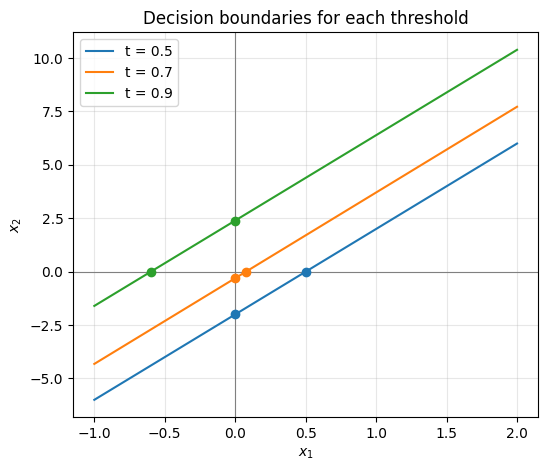

In [7]:
import matplotlib.pyplot as plt

x1 = np.linspace(-1, 2, 200)

fig, ax = plt.subplots(figsize=(6, 5))
for t, ((xa, ya), (xb, yb)) in intersections.items():
    slope = (yb - ya) / (xb - xa)
    x2 = ya + slope * (x1 - xa)               # line through both points
    line, = ax.plot(x1, x2, label=f"t = {t}")
    ax.scatter([xa, xb], [ya, yb], color=line.get_color(), zorder=3)

ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Decision boundaries for each threshold")
ax.legend()
ax.grid(alpha=0.3)
plt.savefig("10__Q4__border_equation_multiple_thresholds.png")
plt.show()

**6.** Para cuatro observaciones se tienen

$$
\mathbf{y} = (1, 0, 1, 0)^T, \qquad \mathbf{p} = (0.8, 0.4, 0.7, 0.3)^T.
$$

- **a)** Evalúe cada factor $p_i^{y_i}(1 - p_i)^{1 - y_i}$.
- **b)** Calcule la verosimilitud $L = \prod_{i=1}^{4} p_i^{y_i}(1 - p_i)^{1 - y_i}$.
- **c)** Calcule $\ln L$ y verifique que coincide con $\sum_{i=1}^{4} \left[ y_i \ln p_i + (1 - y_i) \ln(1 - p_i) \right]$.

In [8]:
p = np.array([0.8, 0.4, 0.7, 0.3])
y = np.array([1, 0, 1, 0])

In [9]:
# item a

#[ REASONING ]
p**y, (1-p)**(1-y) # this mean take p if y=1, otherwise take 1-p (this is a binary event)
# EXTRA: for y = 0, 1-p is being taken, on the other field 1 is put (to later multipy with p**y (which take the ones with y=1)

p**y*(1-p)**(1-y)

array([0.8, 0.6, 0.7, 0.7])

In [10]:
# item b
L = np.prod(p**y*(1-p)**(1-y))
L

0.23519999999999996

In [11]:
# item c
np.log(L), np.sum(y*np.log(p) + (1-y)*np.log(1-p))

(-1.4473190629576653, -1.4473190629576653)

**7.** Considere

$$
X = \begin{pmatrix} 1 & 0 & 1 \\ 1 & 1 & 0 \\ 1 & 1 & 1 \\ 1 & 2 & -1 \end{pmatrix}, \qquad
\mathbf{y} = \begin{pmatrix} 0 \\ 1 \\ 1 \\ 0 \end{pmatrix}, \qquad
\boldsymbol{\beta} = \begin{pmatrix} -0.5 \\ 0.8 \\ -0.4 \end{pmatrix}.
$$

- **a)** Calcule $\mathbf{z} = X\boldsymbol{\beta}$ y $p_i = \sigma(z_i)$.
- **b)** Halle la verosimilitud de las etiquetas observadas.
- **c)** Calcule la entropía cruzada binaria promedio

$$
E(\boldsymbol{\beta}) = -\frac{1}{4} \sum_{i=1}^{4} \left[ y_i \ln p_i + (1 - y_i) \ln(1 - p_i) \right].
$$

In [12]:
X = np.array([
    [1, 0, 1],
    [1, 1, 0],
    [1, 1, 1],
    [1, 2, -1]
])

y = np.array([0, 1, 1, 0])
b = np.array([-0.5, 0.8, -0.4])

In [13]:
# item a
z = X@b
print(f"z={z}")

p = 1/(1+np.exp(-z)) # sigmoid(z)
print(f"p={p}")

z=[-0.9  0.3 -0.1  1.5]
p=[0.289 0.574 0.475 0.818]


In [14]:
# item b
L = np.prod(p**y*(1-p)**(1-y)) # verosimilitud
L

0.03539024516039655

In [15]:
# item c
(-1/4.0)*np.log(L) # avg binary cross entropy 

0.8353297643142346

**9.** Las etiquetas reales y las predicciones de dos modelos son

$$
\begin{array}{c|ccccc}
i & 1 & 2 & 3 & 4 & 5 \\
\hline
y_i & 1 & 0 & 1 & 1 & 0 \\
p_i^{(A)} & 0.90 & 0.20 & 0.65 & 0.55 & 0.10 \\
p_i^{(B)} & 0.70 & 0.05 & 0.80 & 0.40 & 0.30
\end{array}
$$

Calcule la entropía cruzada binaria promedio de cada modelo. ¿Cuál de los dos elegiría según este criterio? Identifique además la observación que aporta la mayor pérdida en cada modelo.

In [16]:
df = pd.DataFrame(
    {
        "y": [1, 0, 1, 1, 0],
        "p_A": [0.90, 0.20, 0.65, 0.55, 0.10],
        "p_B": [0.70, 0.05, 0.80, 0.40, 0.30],
    },
    index=pd.Index([1, 2, 3, 4, 5], name="i"),
)

df["l_A"] = df.p_A**df.y + (1-df.p_A)**(1-df.y)
df["l_B"] = df.p_B**df.y + (1-df.p_B)**(1-df.y)

df

,y,p_A,p_B,l_A,l_B
i,,,,,
1,1,0.900,0.700,1.900,1.700
2,0,0.200,0.050,1.800,1.950
3,1,0.650,0.800,1.650,1.800
4,1,0.550,0.400,1.550,1.400
5,0,0.100,0.300,1.900,1.700


In [17]:
# loss is the negative sum of l, 
# therefore searching the minimum value (biggest apport) to loss
df.l_A.idxmin(), df.l_A.idxmin()

(4, 4)

In [18]:
# since E_A < E_B, then we select model A
# If we observe observation 4, A is not confident of its prediction but clasify it correctly
# in constrast with model B
E_A = -df.l_A.mean()
E_B = -df.l_B.mean()

E_A, E_B

(-1.7599999999999998, -1.7099999999999997)

**11.** Sean

$$
X = \begin{pmatrix} 1 & 0 & 1 \\ 1 & 1 & 0 \\ 1 & 2 & 1 \\ 1 & -1 & 2 \end{pmatrix}, \quad
\mathbf{y} = \begin{pmatrix} 0 \\ 1 \\ 1 \\ 0 \end{pmatrix}, \quad
\boldsymbol{\beta} = \begin{pmatrix} 0 \\ \ln 2 \\ 0 \end{pmatrix}.
$$

Calcule $\mathbf{z} = X\boldsymbol{\beta}$, el vector de probabilidades $\mathbf{p}$ y el gradiente

$$
\nabla E(\boldsymbol{\beta}) = \frac{1}{4} X^T (\mathbf{p} - \mathbf{y}).
$$

Indique las dimensiones de cada matriz o vector que interviene en el producto.

In [19]:
X = np.array([
    [1,  0, 1],
    [1,  1, 0],
    [1,  2, 1],
    [1, -1, 2],
], dtype=float)

y = np.array([0, 1, 1, 0], dtype=float)

b = np.array([0, np.log(2), 0])

In [20]:
z = X@b
print(f"z.shape={z.shape}, z={z}")

p = 1/(1+np.exp(-z))
print(f"p.shape={p.shape}, p={p}")

dE = X.T@(p-y) # gradient of E
print(f"dE.shape={dE.shape}, dE={dE}")

z.shape=(4,), z=[ 0.     0.693  1.386 -0.693]
p.shape=(4,), p=[0.5   0.667 0.8   0.333]
dE.shape=(3,), dE=[ 0.3   -1.067  0.967]


**12.** Considere

$$
X = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 1 & 2 \end{pmatrix}, \qquad
\mathbf{y} = \begin{pmatrix} 0 \\ 0 \\ 1 \end{pmatrix}, \qquad
\boldsymbol{\beta}^{(0)} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}, \qquad
\alpha = 1.
$$

Use la regla

$$
\boldsymbol{\beta}^{(k+1)} = \boldsymbol{\beta}^{(k)} - \frac{\alpha}{3} X^T \left( \mathbf{p}^{(k)} - \mathbf{y} \right)
$$

para calcular $\boldsymbol{\beta}^{(1)}$ y $\boldsymbol{\beta}^{(2)}$. En cada iteración muestre $\mathbf{z}^{(k)}$, $\mathbf{p}^{(k)}$ y el gradiente. Compare también $E(\boldsymbol{\beta}^{(0)})$, $E(\boldsymbol{\beta}^{(1)})$ y $E(\boldsymbol{\beta}^{(2)})$.

In [21]:
X = np.array([
    [1, 0],
    [1, 1],
    [1, 2],
], dtype=float)

y = np.array([0, 0, 1], dtype=float)

b0 = np.zeros(2)

alpha = 1.0

In [22]:
print(f"{'k':>2} | {'b0':^17} | {'b1':^17} | {'z':^26} | {'p':^26} | {'|dE|':>8} | {'E':>8}")
print("-"*122)

k = 10
while k>0:
    z = X@b0
    p = 1/(1+np.exp(-z))
    dE = X.T@(p-y)

    L = np.prod(p**y*(1-p)**(1-y))
    E = (-1/3.0)*np.log(L)

    b1 = b0 - alpha*dE # dE: search direction (gradient of E) 

    #print(f"b0={b0}, b1={b1}, z={z}, p={p}, |dE|={np.linalg.norm(dE)}")
    print(f"{k:>2} | {b0[0]:8.3f} {b0[1]:8.3f} | {b1[0]:8.3f} {b1[1]:8.3f} | "
          f"{z[0]:8.3f} {z[1]:8.3f} {z[2]:8.3f} | {p[0]:8.3f} {p[1]:8.3f} {p[2]:8.3f} | "
          f"{np.linalg.norm(dE):8.4f} | {E:8.4f}")
    
    b0 = b1
    k -= 1

 k |        b0         |        b1         |             z              |             p              |     |dE| |        E
--------------------------------------------------------------------------------------------------------------------------
10 |    0.000    0.000 |   -0.500    0.500 |    0.000    0.000    0.000 |    0.500    0.500    0.500 |   0.7071 |   0.6931
 9 |   -0.500    0.500 |   -1.000    0.755 |   -0.500    0.000    0.500 |    0.378    0.500    0.622 |   0.5613 |   0.5471
 8 |   -1.000    0.755 |   -1.333    1.066 |   -1.000   -0.245    0.510 |    0.269    0.439    0.625 |   0.4557 |   0.4539
 7 |   -1.333    1.066 |   -1.665    1.253 |   -1.333   -0.267    0.800 |    0.209    0.434    0.690 |   0.3811 |   0.3913
 6 |   -1.665    1.253 |   -1.921    1.457 |   -1.665   -0.413    0.840 |    0.159    0.398    0.699 |   0.3277 |   0.3467
 5 |   -1.921    1.457 |   -2.165    1.612 |   -1.921   -0.464    0.994 |    0.128    0.386    0.730 |   0.2884 |   0.3132
 4 |   -2.165   

**14.** Considere un modelo logístico sin intercepto, $p_i(\beta) = \sigma(x_i \beta)$, con $\beta \in [-10, 10]$, y los datos

$$
\begin{array}{c|ccccc}
i & 1 & 2 & 3 & 4 & 5 \\
\hline
x_i & 1 & 2 & -1 & -1 & 5 \\
y_i & 1 & 1 & 0 & 0 & 0
\end{array}
$$

Suponga que, en lugar de la entropía cruzada, se elige como función de costo el error cuadrático medio

$$
M(\beta) = \frac{1}{5} \sum_{i=1}^{5} \big( \sigma(x_i \beta) - y_i \big)^2.
$$

- **a)** Demuestre que

  $$
  M'(\beta) = \frac{2}{5} \sum_{i=1}^{5} \big( \sigma(x_i \beta) - y_i \big)\, \sigma(x_i \beta) \big( 1 - \sigma(x_i \beta) \big)\, x_i.
  $$

- **b)** Use como dato la segunda derivada

  $$
  M''(\beta) = \frac{2}{5} \sum_{i=1}^{5} x_i^2 \left[ q_i^2 + (p_i - y_i)\, q_i (1 - 2p_i) \right],
  $$

  donde

  $$
  p_i = \sigma(x_i \beta), \qquad q_i = p_i (1 - p_i).
  $$

  Verifique que

  $$
  M(0) = \frac{1}{4}, \qquad M'(0) = 0, \qquad M''(0) = \frac{4}{5} > 0,
  $$

  y concluya que $\beta = 0$ es un mínimo local estricto.

- **c)** Calcule $M(10)$ y compruebe que $M(10) < M(0)$. Explique por qué esto demuestra que el mínimo local $\beta = 0$ no es el mínimo global en $[-10, 10]$.

- **d)** Aplique el descenso por gradiente

  $$
  \beta^{(k+1)} = \beta^{(k)} - \alpha M'(\beta^{(k)}), \qquad \alpha > 0,
  $$

  con $\beta^{(0)} = 0$. Demuestre por inducción que $\beta^{(k)} = 0$ para todo $k$ y concluya que, con esta inicialización, el algoritmo queda atrapado en un mínimo local y no converge al mínimo global. Comente qué muestra este ejemplo sobre la elección de la función de costo y la inicialización.

In [23]:
x = np.array([1, 2, -1, -1, 5], dtype=float)
y = np.array([1, 1, 0, 0, 0], dtype=float)

In [24]:
# item b
sigmoid = lambda z: 1/(1+np.exp(-z))
M = lambda b: np.mean((sigmoid(b*x) - y)**2)
dM = lambda b: 2*np.mean((sigmoid(b*x)-y)*sigmoid(b*x)*(1-sigmoid(b*x))*x)
def d2M(b):
    p = sigmoid(b*x)
    q = p*(1-p)
    return 2*np.mean(x**2*(q**2+(p-y)*q*(1-2*p)))

# M(0) says that 0 is a critical point, M''(0) clasify it as a local minimum (only local since M is not convex)
# item c, found a new point x=10 in which M(10) < M(0), that why no convex M doesn't garranty of 0 being global minimum.
M(0), dM(0), d2M(0)

(0.25, 0.0, 0.8)

In [25]:
# item c
M(10), M(10) < M(0)

(0.2000000012365799, True)

In [26]:
b0 = -0.5
alpha=0.5

b_list = [b0]
loss_list = [M(b0)]
k = 256 # max number of iterations
while k > 0:
    g = dM(b0)
    b1 = b0 - alpha*g

    b_list.append(b1)
    loss = M(b1)
    loss_list.append(loss)
    if k % 10 == 0:
        print(f"[k={k}] b0={b0}, b1={b1}, loss={loss}, |g|={np.linalg.norm(g)}")
    
    b0 = b1
    k -= 1

[k=250] b0=-0.02426335686529333, b1=-0.014177883550022943, loss=0.2500817037586463, |g|=0.020170946630540774
[k=240] b0=-0.00013729775293616284, b1=-8.23652276032559e-05, loss=0.2500000027138777, |g|=0.00010986505066581386
[k=230] b0=-8.298508800151707e-07, b1=-4.979100373801783e-07, loss=0.25000000000009914, |g|=6.638816852699847e-07
[k=220] b0=-5.017778616922642e-09, b1=-3.010667139902268e-09, loss=0.25000000000000006, |g|=4.014222954040747e-09
[k=210] b0=-3.0340576584564744e-11, b1=-1.8204373431019276e-11, loss=0.25, |g|=2.4272406307090932e-11
[k=200] b0=-1.8347754436915316e-13, b1=-1.1011400690192282e-13, loss=0.25, |g|=1.4672707493446068e-13
[k=190] b0=-1.112310344224952e-15, b1=-6.682211343748893e-16, loss=0.25, |g|=8.881784197001252e-16
[k=180] b0=-4.649624058480168e-17, b1=-4.649624058480168e-17, loss=0.25, |g|=0.0
[k=170] b0=-4.649624058480168e-17, b1=-4.649624058480168e-17, loss=0.25, |g|=0.0
[k=160] b0=-4.649624058480168e-17, b1=-4.649624058480168e-17, loss=0.25, |g|=0.0
[k=

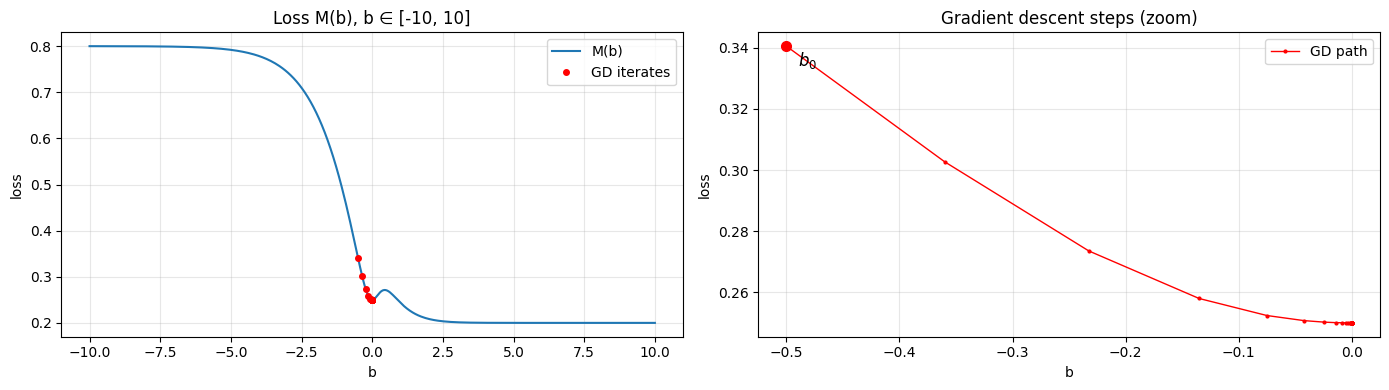

In [27]:
# when b0 is initialized with a negative number close to 0 (e.g. b0=-0.5), it get trapped on b=0 (local optimal)
# when b0 is initialized with a negetive close to -10, it also get trapped, since gradient is also 0 in this zone.
# when b0 is initialized with a positive number close to 0 (e.g. b0=0.5), it converge to the global minimum.

import matplotlib.pyplot as plt

bs = np.linspace(-10, 10, 400)
losses = [M(b) for b in bs]

# zoom window around the iterates
b_min, b_max = min(b_list), max(b_list)
pad = 0.5*(b_max - b_min) + 1e-3
bz = np.linspace(b_min - pad, b_max + pad, 200)
lz = [M(b) for b in bz]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# left: full loss
ax1.plot(bs, losses, label="M(b)")
ax1.plot(b_list, loss_list, "o", ms=4, color="red", label="GD iterates")
ax1.set_xlabel("b"); ax1.set_ylabel("loss"); ax1.set_title("Loss M(b), b ∈ [-10, 10]")
ax1.grid(alpha=0.3); ax1.legend()

# right: zoom on the steps
ax2.plot(b_list, loss_list, "o-", ms=2, lw=1, color="red", label="GD path")
ax2.plot(b_list[0], loss_list[0], "o", ms=7, color="red")   # highlight start
ax2.annotate(r"$b_0$", (b_list[0], loss_list[0]),
             textcoords="offset points", xytext=(8, -14), fontsize=12)
ax2.set_xlabel("b"); ax2.set_ylabel("loss"); ax2.set_title("Gradient descent steps (zoom)")
ax2.grid(alpha=0.3); ax2.legend()

plt.tight_layout()
plt.savefig("10__Q14__noconvex-loss-logitic-regression.png")
plt.show()

**15.** Considere

$$
X = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 1 & 2 \end{pmatrix}, \qquad
\mathbf{y} = \begin{pmatrix} 0 \\ 1 \\ 0 \end{pmatrix}, \qquad
\boldsymbol{\beta}^{(0)} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}.
$$

Para la entropía cruzada binaria promedio, sean

$$
\mathbf{p} = \sigma(X\boldsymbol{\beta}), \qquad W = \operatorname{diag}\big( p_i (1 - p_i) \big),
$$

de modo que

$$
\nabla E(\boldsymbol{\beta}) = \frac{1}{3} X^T (\mathbf{p} - \mathbf{y}), \qquad H(\boldsymbol{\beta}) = \frac{1}{3} X^T W X.
$$

Use la actualización de Newton

$$
\boldsymbol{\beta}^{(k+1)} = \boldsymbol{\beta}^{(k)} - H(\boldsymbol{\beta}^{(k)})^{-1} \nabla E(\boldsymbol{\beta}^{(k)}).
$$

- **a)** Calcule $\mathbf{p}^{(0)}$, $W^{(0)}$, el gradiente y la Hessiana en $\boldsymbol{\beta}^{(0)}$. Obtenga $\boldsymbol{\beta}^{(1)}$.

- **b)** Realice una segunda iteración para calcular $\boldsymbol{\beta}^{(2)}$.

- **c)** Verifique que

  $$
  \boldsymbol{\beta}^{*} = \begin{pmatrix} -\ln 2 \\ 0 \end{pmatrix}
  $$

  anula el gradiente y explique por qué es el mínimo global.

- **d)** Compare las dos aproximaciones con $\boldsymbol{\beta}^{*}$ y calcule la pérdida en cada iteración.

In [28]:
import numpy as np

X = np.array([
    [1, 0],
    [1, 1],
    [1, 2],
], dtype=float)

y = np.array([0, 1, 0], dtype=float)

beta0 = np.zeros(2)

b_star = np.array([-np.log(2), 0])

In [29]:
# [item a] iteration 1
b0 = beta0
print(f"beta={b0}")

z = X@b0
print(f"z={z}")

p = 1/(1+np.exp(-z))
print(f"p={p}")

# gradient of 
dE = X.T@(p-y) / 3.0
print(f"dE={dE}")

# hessian on b0
W = np.diag(p*(1-p))
print(f"W:\n{W}")

H = X.T@W@X / 3.0
print(f"H:\n{H}")

invH = np.linalg.inv(H)
print(f"invH:\n{invH}")

# newton step
b1 = b0 - invH@dE
print(f"b1={b1}, b*={b_star}")

# loss [item d]
E = -np.mean(y*np.log(p) + (1-y)*np.log(1-p))
print(f"E: {E}")

beta=[0. 0.]
z=[0. 0. 0.]
p=[0.5 0.5 0.5]
dE=[0.167 0.167]
W:
[[0.25 0.   0.  ]
 [0.   0.25 0.  ]
 [0.   0.   0.25]]
H:
[[0.25  0.25 ]
 [0.25  0.417]]
invH:
[[10. -6.]
 [-6.  6.]]
b1=[-0.667  0.   ], b*=[-0.693  0.   ]
E: 0.6931471805599453


In [30]:
# [item b] iteration 2
b0 = b1 # from previous iteration
print(f"beta={b0}")

z = X@b0
print(f"z={z}")

p = 1/(1+np.exp(-z))
print(f"p={p}")

# gradient of 
dE = X.T@(p-y) / 3.0
print(f"dE={dE}")

# hessian on b0
W = np.diag(p*(1-p))
print(f"W:\n{W}")

H = X.T@W@X / 3.0
print(f"H:\n{H}")

invH = np.linalg.inv(H)
print(f"invH:\n{invH}")

# newton step
b1 = b0 - invH@dE
print(f"b1={b1}, b*={b_star}") # almost converged to the optimal beta

# loss [item d]
E = -np.mean(y*np.log(p) + (1-y)*np.log(1-p))
print(f"E: {E}")

beta=[-0.667  0.   ]
z=[-0.667 -0.667 -0.667]
p=[0.339 0.339 0.339]
dE=[0.006 0.006]
W:
[[0.224 0.    0.   ]
 [0.    0.224 0.   ]
 [0.    0.    0.224]]
H:
[[0.224 0.224]
 [0.224 0.374]]
invH:
[[11.153 -6.692]
 [-6.692  6.692]]
b1=[-0.693  0.   ], b*=[-0.693  0.   ]
E: 0.6365923090742943


In [31]:
# item c
# check b* is the global minimum

b = b_star

z = X@b
print(f"z={z}")

p = 1/(1+np.exp(-z))
print(f"p={p}")

# we expect gradient of E in b* be 0 (b* stationary point)
dE = X.T@(p-y) / 3.0
print(f"dE={dE}")


# we expect hessian defined possitive (eigenvalues > 0)
W = np.diag(p*(1-p))
print(f"W:\n{W}")

H = X.T@W@X / 3.0
print(f"H:\n{H}")

# eigenvalues of hessian at b* must be positives, therefore b* is an local minimum, but since E is convex, it is global minimum.
print(f"eigvals(H): {np.linalg.eigvalsh(H)}")

z=[-0.693 -0.693 -0.693]
p=[0.333 0.333 0.333]
dE=[-0. -0.]
W:
[[0.222 0.    0.   ]
 [0.    0.222 0.   ]
 [0.    0.    0.222]]
H:
[[0.222 0.222]
 [0.222 0.37 ]]
eigvals(H): [0.062 0.531]


In [32]:
# EXTRA: multiple iterations + plot of loss + convergence to the b* (contour lines)

def loss(b):
    z = X@b
    p = 1/(1+np.exp(-z))
    p = np.clip(p, 1e-12, 1-1e-12) # log(0) is not defined
    E = -np.mean(y*np.log(p) + (1-y)*np.log(1-p))
    return E

k = 10
b_star = np.array([-np.log(2), 0])
b0 = np.zeros(2)
b_list = b0
E_list = [loss(b0)]
while k > 0:
    z = X@b0
    p = 1/(1+np.exp(-z))
    dE = X.T@(p-y) / 3.0
    W = np.diag(p*(1-p))
    H = X.T@W@X / 3.0
    invH = np.linalg.inv(H)

    b1 = b0 - invH@dE

    E = loss(b1) # loss
    print(f"b0={b0}, b1={b1}, |dE|={np.linalg.norm(dE)}, E={E}") # almost converged to the optimal beta

    b_list = np.vstack([b_list, b1])
    E_list.append(E)

    b0 = b1
    k -= 1

b0=[0. 0.], b1=[-0.667  0.   ], |dE|=0.23570226039551584, E=0.6365923090742943
b0=[-0.667  0.   ], b1=[-0.693  0.   ], |dE|=0.008358423449046618, E=0.6365141697333023
b0=[-0.693  0.   ], b1=[-0.693  0.   ], |dE|=3.575877146919344e-05, E=0.6365141682948128
b0=[-0.693  0.   ], b1=[-0.693  0.   ], |dE|=6.780248544632699e-10, E=0.6365141682948128
b0=[-0.693  0.   ], b1=[-0.693  0.   ], |dE|=5.233641528945917e-17, E=0.6365141682948128
b0=[-0.693  0.   ], b1=[-0.693  0.   ], |dE|=5.233641528945917e-17, E=0.6365141682948128
b0=[-0.693  0.   ], b1=[-0.693  0.   ], |dE|=5.233641528945917e-17, E=0.6365141682948128
b0=[-0.693  0.   ], b1=[-0.693  0.   ], |dE|=5.233641528945917e-17, E=0.6365141682948128
b0=[-0.693  0.   ], b1=[-0.693  0.   ], |dE|=5.233641528945917e-17, E=0.6365141682948128
b0=[-0.693  0.   ], b1=[-0.693  0.   ], |dE|=5.233641528945917e-17, E=0.6365141682948128


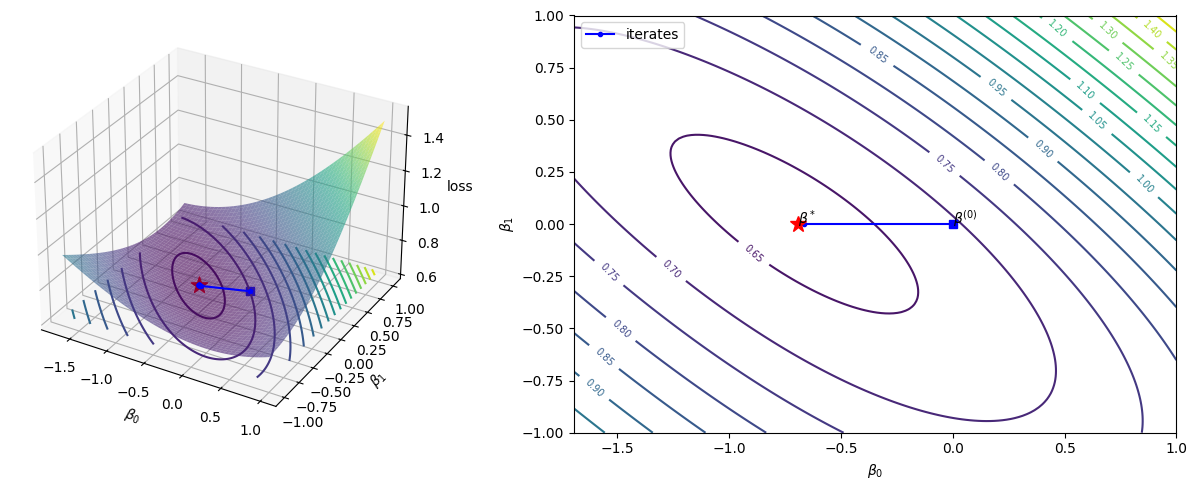

In [33]:
L = np.array(E_list)
E_star = loss(b_star)

pad = 1.0
lo = np.minimum(b_list.min(0), b_star) - pad
hi = np.maximum(b_list.max(0), b_star) + pad
g0 = np.linspace(lo[0], hi[0], 150)
g1 = np.linspace(lo[1], hi[1], 150)
B0, B1 = np.meshgrid(g0, g1)
Z = np.array([[loss(np.array([u, v])) for u, v in zip(r0, r1)]
              for r0, r1 in zip(B0, B1)])

fig = plt.figure(figsize=(13, 5))

# 3D surface + iterates
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(B0, B1, Z, cmap="viridis", alpha=0.6)
ax.contour(B0, B1, Z, levels=20, cmap="viridis", offset=Z.min())
ax.plot(b_list[:, 0], b_list[:, 1], L, "b.-", zorder=10)
ax.scatter(*b_list[0], L[0], c="b", marker="s", s=40)
ax.scatter(*b_star, E_star, c="r", marker="*", s=150)
ax.set_xlabel(r"$\beta_0$"); ax.set_ylabel(r"$\beta_1$"); ax.set_zlabel("loss")

# contour + iterates
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(B0, B1, Z, levels=20, cmap="viridis")
ax2.clabel(cs, fontsize=7)
ax2.plot(b_list[:, 0], b_list[:, 1], "b.-", label="iterates")
ax2.plot(*b_list[0], "bs"); ax2.annotate(r"$\beta^{(0)}$", b_list[0])
ax2.plot(*b_star, "r*", ms=12); ax2.annotate(r"$\beta^*$", b_star)
ax2.set_xlabel(r"$\beta_0$"); ax2.set_ylabel(r"$\beta_1$"); ax2.legend()

plt.tight_layout()
plt.savefig("10__Q15__convergence-newton.png")
plt.show()